In [2]:
# Long short Term memory(LSTM)
import math
import pandas_datareader as web
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from keras.models import Sequential
from keras.layers import Dense, LSTM
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')

In [3]:
# Get the stock quote
import yfinance as yf
df = yf.download('AAPL', start = '2012-01-01', end = '2019-12-17')
# Show the Data
df.head(10)

/tmp/ipython-input-642166010.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download('AAPL', start = '2012-01-01', end = '2019-12-17')
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2012-01-03,12.345171,12.383297,12.278227,12.290235,302220800
2012-01-04,12.411515,12.448741,12.286632,12.308246,260022000
2012-01-05,12.549311,12.564921,12.388402,12.456849,271269600
2012-01-06,12.680500,12.691007,12.585036,12.601547,318292800
2012-01-09,12.660383,12.841104,12.648975,12.773560,394024400
2012-01-10,12.705713,12.788569,12.653478,12.785867,258196400
2012-01-11,12.684999,12.694005,12.587734,12.688901,215084800
2012-01-12,12.650178,12.695508,12.570925,12.676896,212587200


In [4]:
# Get the number of rows and columns
df.shape

(2002, 5)

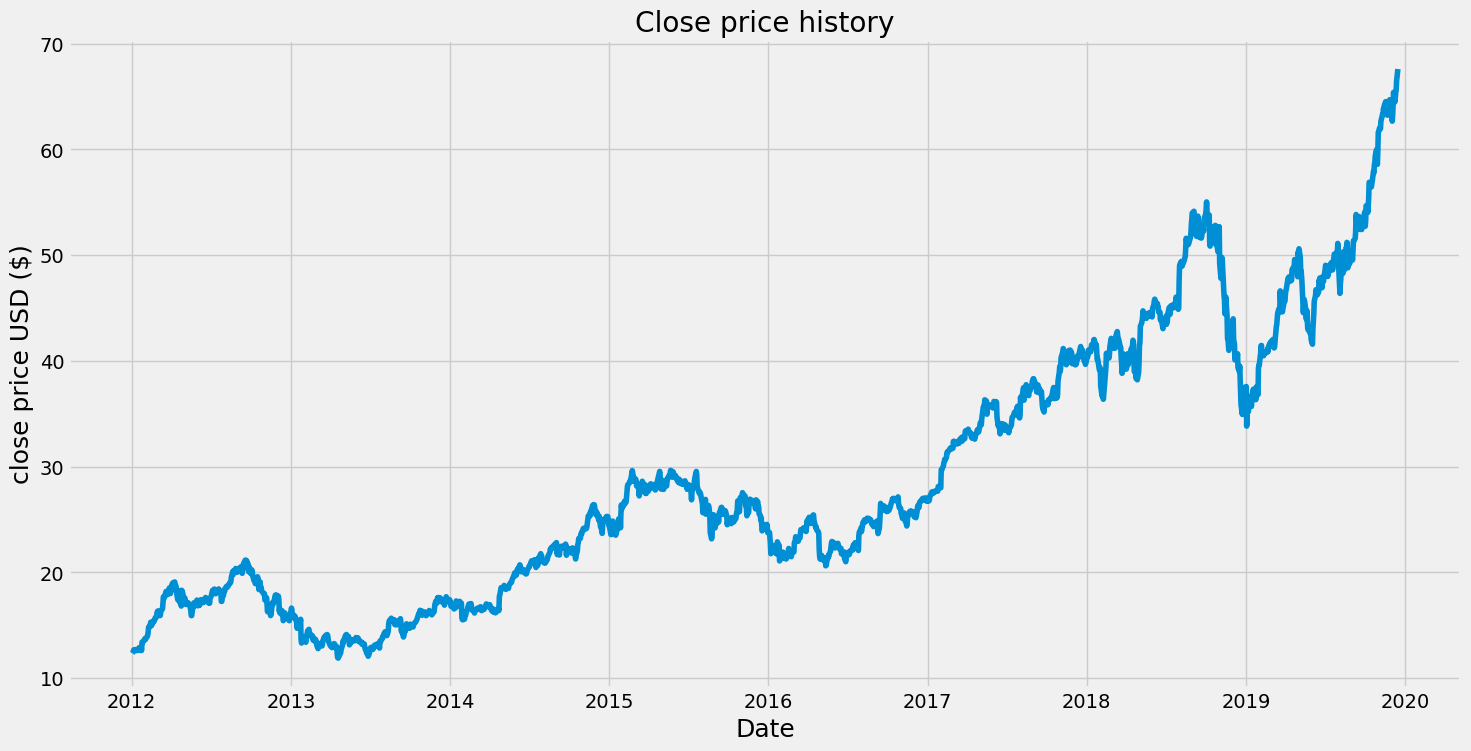

In [5]:
# Visualize the colssing price history
plt.figure(figsize=(16,8))
plt.title('Close price history')
plt.plot(df['Close'])
plt.xlabel('Date', fontsize = 18)
plt.ylabel('close price USD ($)', fontsize=18)
plt.show()

In [6]:
from os import close
# Create new dataframe with only the close column
data = df['Close']
# Convert the dataframe to numpy array
dataset= data.values
# get the the number  of rows to train the model on
train_data_len= math.ceil(len(dataset)*.8)
train_data_len

1602

In [7]:
df.shape

(2002, 5)

In [8]:
df.head()

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2012-01-03,12.345171,12.383297,12.278227,12.290235,302220800
2012-01-04,12.411515,12.448741,12.286632,12.308246,260022000
2012-01-05,12.549311,12.564921,12.388402,12.456849,271269600
2012-01-06,12.680500,12.691007,12.585036,12.601547,318292800
2012-01-09,12.660383,12.841104,12.648975,12.773560,394024400


In [9]:
df.tail(10)

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2019-12-03,62.660629,62.679947,61.897446,62.385301,114430400
2019-12-04,63.213680,63.592858,62.957677,63.051871,67181600
2019-12-05,64.141090,64.215966,63.452783,63.708787,74424400
2019-12-06,65.380066,65.450107,64.556505,64.599983,106075600
2019-12-09,64.464722,65.401787,63.979278,65.208579,128042400
2019-12-10,64.841476,65.225482,64.208706,64.870457,90420400
2019-12-11,65.394539,65.474242,64.846306,64.921175,78756800
2019-12-12,65.561211,65.826877,64.561349,64.672443,137310400


In [10]:
scaler = MinMaxScaler(feature_range=(0,1))
scaled_data = scaler.fit_transform(dataset.reshape(-1, 1))
scaled_data

array([[0.00805069],
       [0.00924194],
       [0.01171613],
       ...,
       [0.96357382],
       [0.97957562],
       [1.        ]])

In [11]:
# Scale the data
scaler = MinMaxScaler(feature_range=(0,1))
scaled_data = scaler.fit_transform(dataset.reshape(-1, 1))
scaled_data

array([[0.00805069],
       [0.00924194],
       [0.01171613],
       ...,
       [0.96357382],
       [0.97957562],
       [1.        ]])

In [12]:
# Create training dataset
# Create the scaled training data set
train_data= scaled_data[0:train_data_len, :]
# Split the data into x_train and y_train data sets
x_train = []
y_train = []
for i in range(60, len(train_data)):
  x_train.append(train_data[i-60:i, 0])
  y_train.append(train_data[i, 0])
  if i<=61:
    print(x_train)
    print(y_train)
    print()

[array([0.00805069, 0.00924194, 0.01171613, 0.01407171, 0.0137105 ,
       0.01452443, 0.01415248, 0.01352726, 0.01267561, 0.01531144,
       0.01768852, 0.01695549, 0.01293973, 0.01677219, 0.01299899,
       0.0271485 , 0.02605427, 0.02748269, 0.03057131, 0.03244167,
       0.03228533, 0.0317086 , 0.03416665, 0.03647907, 0.03909873,
       0.04333008, 0.05221864, 0.05235342, 0.05730172, 0.06099945,
       0.05464423, 0.05709152, 0.05704305, 0.0639048 , 0.06292909,
       0.06473479, 0.06797972, 0.06978554, 0.0749871 , 0.07877652,
       0.07987069, 0.08025344, 0.07377447, 0.07221116, 0.07244291,
       0.07853384, 0.08024803, 0.0839297 , 0.09260795, 0.10418638,
       0.10201947, 0.10202471, 0.11039592, 0.11301558, 0.11115064,
       0.10944727, 0.1076738 , 0.11356532, 0.11760807, 0.11930055])]
[np.float64(0.11511772865447334)]

[array([0.00805069, 0.00924194, 0.01171613, 0.01407171, 0.0137105 ,
       0.01452443, 0.01415248, 0.01352726, 0.01267561, 0.01531144,
       0.01768852, 0.01

In [13]:
# Convert the x_train and y_train to numpy array
x_train, y_train = np.array(x_train), np.array(y_train)

In [14]:
# Reshape the data
x_train = np.reshape(x_train, (x_train.shape[0], x_train.shape[1], 1))
x_train.shape

(1542, 60, 1)

In [15]:
# Biuld the LSTM model
model = Sequential()
model.add(LSTM(50, return_sequences=True, input_shape=(x_train.shape[1], 1)))
model.add(LSTM(50, return_sequences=False))
model.add(Dense(25))
model.add(Dense(1))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [16]:
# Compile the model
model.compile(optimizer='adam', loss='mean_squared_error')

In [17]:
# Train the model
model.fit(x_train, y_train, batch_size=1, epochs=1)

1542/1542 ━━━━━━━━━━━━━━━━━━━━ 22s 13ms/step - loss: 0.0026


In [18]:
# Create the testing data set
# Create new array containing scaled values from index 1543 to 2002
test_data = scaled_data[train_data_len - 60: , :]
# Create the data sets x_test and y_test
x_test = []
y_test = dataset[train_data_len:, :]
for i in range(60, len(test_data)):
  x_test.append(test_data[i-60:i, 0])

In [19]:
# Convert the data to a numpy array
x_test = np.array(x_test)

In [20]:
# Reshape the data
x_test = np.reshape(x_test, (x_test.shape[0], x_test.shape[1], 1))

In [21]:
# Get the model predicted price values
predictions = model.predict(x_test)
predictions = scaler.inverse_transform(predictions)


13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


In [22]:
# Get the root mean squared error (RMSE)
rmse = np.sqrt(np.mean(predictions - y_test)**2)
rmse

np.float64(0.09135816574096679)

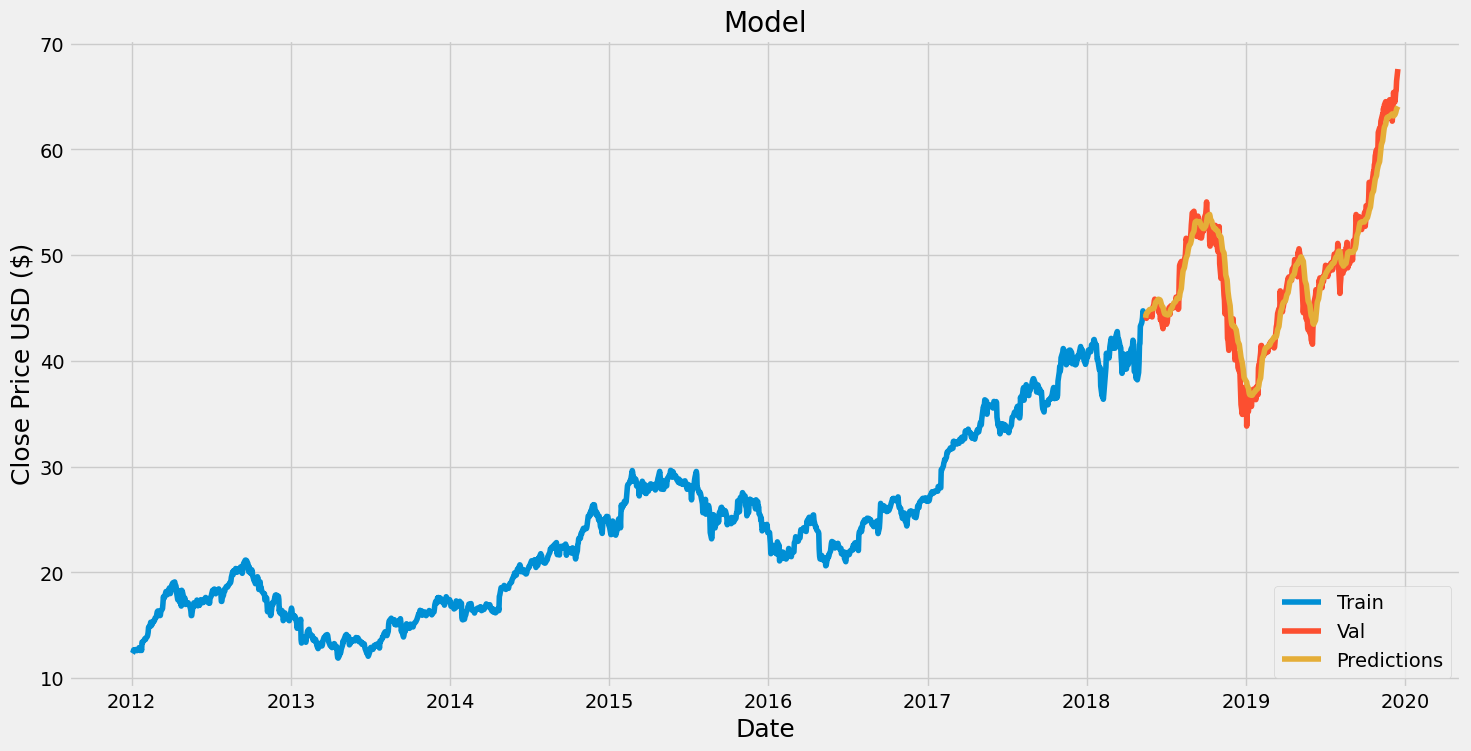

In [23]:
# Plot the data
train = data[:train_data_len]
valid = pd.DataFrame(data[train_data_len:].values, columns=['Close'], index=data[train_data_len:].index)
valid['Predictions'] = predictions.flatten()
# Visualize the data
plt.figure(figsize=(16,8))
plt.title('Model')
plt.xlabel('Date', fontsize=18)
plt.ylabel('Close Price USD ($)', fontsize=18)
plt.plot(train)
plt.plot(valid[['Close', 'Predictions']])
plt.legend(['Train', 'Val', 'Predictions'], loc='lower right')
plt.show()

In [24]:
# Show the valid and predicted prices
valid

,Close,Predictions
Date,,
2018-05-16,44.463593,44.065426
2018-05-17,44.182411,44.319721
2018-05-18,44.021744,44.497913
2018-05-21,44.333652,44.606598
2018-05-22,44.222584,44.690182
...,...,...
2019-12-10,64.841476,63.354301
2019-12-11,65.394539,63.470089
2019-12-12,65.561211,63.628937


In [25]:
# Get the quote
apple_quote = yf.download('AAPL', start = '2012-01-01', end = '2019-12-17')


/tmp/ipython-input-139687017.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  apple_quote = yf.download('AAPL', start = '2012-01-01', end = '2019-12-17')
[*********************100%***********************]  1 of 1 completed


In [29]:
# Craete new dataframe
df_new = apple_quote.filter([('Close', 'AAPL')])
# Get teh the last 60 day closing price values and convert the dataframe to array
last_60_days = df_new[-60:].values
# Scale the data to be values between 0 and 1
last_60_days_scaled = scaler.transform(last_60_days)
# Create an empty list
X_test = []
# Append the past 60 days
X_test.append(last_60_days_scaled)
# convert the x_test data set to a numpy array
x_test = np.array(X_test)
# Reshape the data
x_test = np.reshape(x_test, (x_test.shape[0], x_test.shape[1], 1))
# Get the predicted scaled price
pred_price = model.predict(x_test)
#undo the scaling
pred_price = scaler.inverse_transform(pred_price)
print(pred_price)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
[[64.397]]
